# PRACTICUM DE ÎNVĂȚARE AUTOMATĂ: CODUL ȘI ALGORITMUL KNN
**Teme:** Preprocesarea datelor, Codificare categorială, Normalizare, Algoritmul K cei mai apropiați vecini (KNN), Ajustarea hiperparametrilor, Valori metrice ale distanței, Intel® Extension for Scikit-learn și Combaterea supraantrenării (Overfitting).

### Exercițiul 1: Ingineria caracteristicilor și eliminarea coloanelor irelevante
În setul de date Orange Telecom Churn, coloanele `state`, `area_code` și `phone_number` au fost eliminate în notebook. Scrieți un bloc de cod în Pandas care analizează cardinalitatea unică a fiecărei coloane categoriale rămase și eliminate. Explicați din punct de vedere matematic de ce aplicarea `OneHotEncoder` sau `LabelBinarizer` pe o coloană cu sute de valori unice (de exemplu, `phone_number`) va distruge eficiența spațială și va genera un risc ridicat de supraantrenare (overfitting) pentru algoritmul KNN.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

df_raw = pd.read_csv('Orange_Telecom_Churn_Data - Orange_Telecom_Churn_Data.csv')
print('Dimensiune:', df_raw.shape)

# Cardinalitatea fiecarei coloane categoriale / de tip identificator
cat_cols = ['state', 'area_code', 'phone_number', 'intl_plan', 'voice_mail_plan', 'churned']
card = pd.DataFrame({
    'valori_unice': df_raw[cat_cols].nunique(),
    'raport_unic/randuri': (df_raw[cat_cols].nunique() / len(df_raw)).round(4),
    'tip': df_raw[cat_cols].dtypes.astype(str),
})
card['status'] = np.where(card.index.isin(['state', 'area_code', 'phone_number']), 'eliminata', 'pastrata')
card

Dimensiune: (5000, 21)


,valori_unice,raport_unic/randuri,tip,status
state,51,0.0102,str,eliminata
area_code,3,0.0006,int64,eliminata
phone_number,5000,1.0000,str,eliminata
intl_plan,2,0.0004,str,pastrata
voice_mail_plan,2,0.0004,str,pastrata
churned,2,0.0004,bool,pastrata


In [2]:
# Ce s-ar intampla daca am aplica one-hot encoding pe coloanele eliminate?
n = len(df_raw)
num_cols = df_raw.select_dtypes('number').drop(columns='area_code').shape[1]
for col in ['area_code', 'state', 'phone_number']:
    k = df_raw[col].nunique()
    print(f'{col:13s}: +{k:5d} coloane binare -> {num_cols + k:5d} dimensiuni; '
          f'matrice densa {n} x {k} = {n * k:,} celule')

# Distanta dintre doi clienti diferiti doar prin phone_number dupa one-hot:
# vectorii one-hot difera in exact 2 pozitii -> contributie constanta sqrt(2)
a = np.zeros(df_raw['phone_number'].nunique()); a[0] = 1
b = np.zeros_like(a); b[1] = 1
print('\nContributia phone_number la distanta euclidiana intre ORICARE 2 clienti:', np.linalg.norm(a - b))
print('Diametrul spatiului celorlalte caracteristici scalate [0,1]: sqrt(%d) = %.2f' % (num_cols, np.sqrt(num_cols)))

area_code    : +    3 coloane binare ->    18 dimensiuni; matrice densa 5000 x 3 = 15,000 celule
state        : +   51 coloane binare ->    66 dimensiuni; matrice densa 5000 x 51 = 255,000 celule
phone_number : + 5000 coloane binare ->  5015 dimensiuni; matrice densa 5000 x 5000 = 25,000,000 celule

Contributia phone_number la distanta euclidiana intre ORICARE 2 clienti: 1.4142135623730951
Diametrul spatiului celorlalte caracteristici scalate [0,1]: sqrt(15) = 3.87


**Raspuns:**

- `phone_number` are 5000 de valori unice la 5000 de randuri (raport 1.0) - este un identificator, nu o caracteristica. `state` are 51 de valori, `area_code` doar 3. Coloanele pastrate (`intl_plan`, `voice_mail_plan`) sunt binare si se codifica intr-o singura coloana.
- **Eficienta spatiala:** one-hot pe o coloana cu $m$ valori unice adauga $m$ coloane. Pentru `phone_number`, $m = n = 5000$, deci matricea devine $n \times n$ = 25 de milioane de celule (99.98% zerouri), iar cautarea vecinilor costa $O(n \cdot d)$ cu $d \approx n$, adica $O(n^2)$ per interogare.
- **Overfitting / distorsionarea distantei:** doi clienti diferiti au vectori one-hot care difera in exact 2 pozitii, deci contributia la distanta este mereu $\sqrt{2}$ - aceeasi pentru oricare doi clienti. Coloana nu aduce nicio informatie de similaritate, ci doar adauga zgomot constant si mareste dimensionalitatea (blestemul dimensionalitatii, vezi Ex. 10). Mai mult, un client nou are un numar de telefon nevazut, deci caracteristica nu poate generaliza: modelul ar memora identitatea clientilor din train.
- `state` (51 coloane) are acelasi efect, mai slab: cu doar ~100 de clienti pe stat, KNN ar invata particularitati locale si ar creste varianta modelului.

### Exercițiul 2: Impactul scalării datelor asupra distanței euclidiene
Folosind `MinMaxScaler`, toate caracteristicile numerice sunt aduse în intervalul [0, 1]. Să presupunem că avem două caracteristici: `account_length` (valori de la 1 la 250) și `total_day_charge` (valori de la 0 la 100). Calculați manual sau scrieți cod care arată cum distanța euclidiană între doi clienți este distorsionată dacă nu se aplică scalarea. Ce se întâmplă dacă se folosește `StandardScaler` în loc de `MinMaxScaler` atunci când în distribuția datelor există valori anormale (outliers)?

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df = pd.read_csv('Orange_Telecom_Churn_Data - Orange_Telecom_Churn_Data.csv')
pair = df[['account_length', 'total_day_charge']]
print(pair.describe().loc[['min', 'max', 'std']])

# Doi clienti: diferenta mare la total_day_charge, mica la account_length
c1 = np.array([100, 20.0])
c2 = np.array([110, 50.0])
c3 = np.array([160, 21.0])

def dist(a, b):
    return np.linalg.norm(a - b)

print('\nFARA scalare:')
print(f'  d(c1, c2) = {dist(c1, c2):.2f}   (difera mult la charge: 30 USD)')
print(f'  d(c1, c3) = {dist(c1, c3):.2f}   (difera doar la vechime: 60 zile)')

mm = MinMaxScaler().fit(pair)
s1, s2, s3 = mm.transform(pd.DataFrame([c1, c2, c3], columns=pair.columns))
print('\nCU MinMaxScaler:')
print(f'  d(c1, c2) = {dist(s1, s2):.3f}')
print(f'  d(c1, c3) = {dist(s1, s3):.3f}')

# Contributia fiecarei caracteristici la patratul distantei
raw_contrib = (c1 - c2) ** 2 / ((c1 - c2) ** 2).sum()
sc_contrib = (s1 - s2) ** 2 / ((s1 - s2) ** 2).sum()
print('\nPondere in d^2(c1,c2) [account_length, total_day_charge]')
print('  fara scalare:', raw_contrib.round(3))
print('  MinMax      :', sc_contrib.round(3))

     account_length  total_day_charge
min         1.00000          0.000000
max       243.00000         59.760000
std        39.69456          9.162069

FARA scalare:
  d(c1, c2) = 31.62   (difera mult la charge: 30 USD)
  d(c1, c3) = 60.01   (difera doar la vechime: 60 zile)

CU MinMaxScaler:
  d(c1, c2) = 0.504
  d(c1, c3) = 0.248

Pondere in d^2(c1,c2) [account_length, total_day_charge]
  fara scalare: [0.1 0.9]
  MinMax      : [0.007 0.993]


,IQR date normale (fara outlieri),IQR date normale (cu outlieri),interval cu outlieri
scaler,,,
MinMaxScaler,0.206,0.026,"[0.00, 1.00]"
StandardScaler,1.345,0.782,"[-1.97, 28.56]"
RobustScaler,1.000,0.998,"[-2.48, 36.52]"


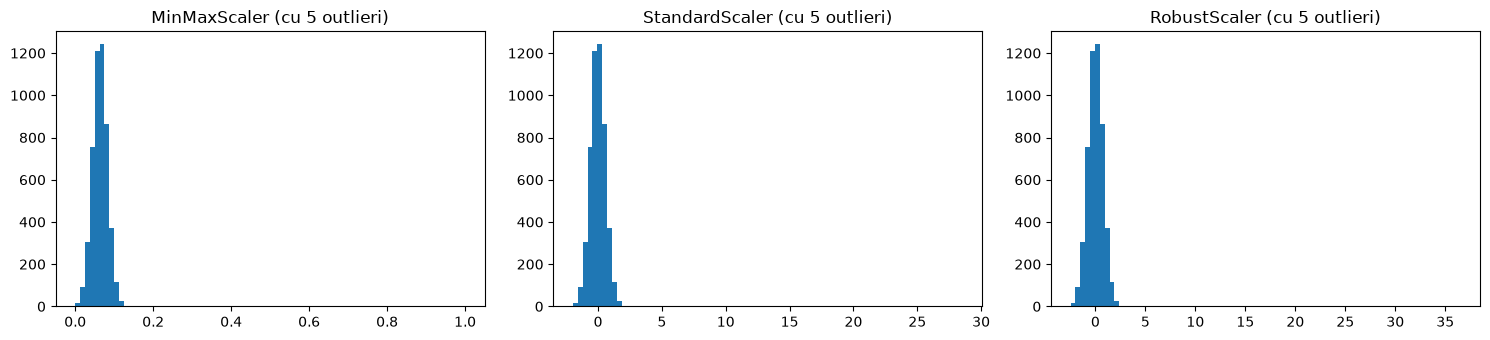

In [4]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler

# Efectul outlierilor: adaugam 5 valori extreme pe total_day_charge
rng = np.random.default_rng(0)
x = df['total_day_charge'].to_numpy().reshape(-1, 1)
x_out = np.vstack([x, rng.uniform(400, 500, size=(5, 1))])

scalers = {'MinMaxScaler': MinMaxScaler(), 'StandardScaler': StandardScaler(), 'RobustScaler': RobustScaler()}
rows = []
for name, sc in scalers.items():
    clean = sc.fit_transform(x).ravel()
    dirty = sc.fit_transform(x_out).ravel()[:len(x)]
    rows.append({'scaler': name,
                 'IQR date normale (fara outlieri)': np.subtract(*np.percentile(clean, [75, 25])),
                 'IQR date normale (cu outlieri)': np.subtract(*np.percentile(dirty, [75, 25])),
                 'interval cu outlieri': f'[{sc.fit_transform(x_out).min():.2f}, {sc.fit_transform(x_out).max():.2f}]'})
display(pd.DataFrame(rows).set_index('scaler').round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, sc) in zip(axes, scalers.items()):
    ax.hist(sc.fit_transform(x_out).ravel(), bins=80)
    ax.set_title(f'{name} (cu 5 outlieri)')
plt.tight_layout()

**Raspuns:**

- **Fara scalare** distanta este dominata de caracteristica cu intervalul cel mai mare. `account_length` are intervalul ~1-243, iar `total_day_charge` ~0-60, deci o diferenta de 60 de zile de vechime (c1 vs c3, d = 60.01) pare "mai mare" decat o diferenta de 30 USD la factura (c1 vs c2, d = 31.62). Dupa `MinMaxScaler` ordinea se inverseaza (0.248 vs 0.504): 30 USD inseamna jumatate din intervalul facturii, in timp ce 60 de zile sunt doar un sfert din intervalul vechimii. Fara scalare, KNN ar alege vecinii aproape doar dupa `account_length`.
- **Outlieri:** `MinMaxScaler` foloseste min si max, deci un singur outlier comprima toate datele normale intr-un interval foarte mic (IQR scade de la 0.206 la 0.026 - de 8 ori). Caracteristica respectiva aproape dispare din distanta. `StandardScaler` foloseste media si deviatia standard, care sunt si ele influentate de outlieri (IQR scade de la 1.345 la 0.782), dar mai putin; in schimb nu mai garanteaza un interval fix (valori pana la 28.6). Cel mai robust este `RobustScaler` (mediana si IQR), care practic nu este afectat (IQR ramane ~1.0).

### Exercițiul 3: Optimizare hardware cu Intel® Extension for Scikit-learn
În notebook este activată extensia `from sklearnex import patch_sklearn; patch_sklearn()`. Explicați cum această bibliotecă accelerează operațiunile de căutare a celor mai apropiați vecini (de exemplu, utilizând structuri de date indexate precum KD-Tree sau Ball-Tree, optimizate cu instrucțiuni AVX-512). Scrieți un fragment de cod care măsoară timpul de execuție (`timeit`) pentru antrenarea `KNeighborsClassifier` cu și fără patch-ul Intel pe un set sintetic de 100.000 de obiecte.

In [5]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Crearea de date sintetice
rng = np.random.default_rng(42)
X = rng.random((100000, 10))
y = rng.integers(0, 2, 100000)
X_query = X[:2000]

def benchmark(label, repeats=3):
    from sklearn.neighbors import KNeighborsClassifier  # re-import dupa (un)patch
    fit_t, pred_t = [], []
    for _ in range(repeats):
        knn = KNeighborsClassifier(n_neighbors=5, algorithm='kd_tree')
        t0 = time.perf_counter(); knn.fit(X, y); fit_t.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); knn.predict(X_query); pred_t.append(time.perf_counter() - t0)
    print(f'{label:22s} fit: {min(fit_t):.3f}s  predict(2000): {min(pred_t):.3f}s  [{type(knn).__module__}]')
    return min(fit_t), min(pred_t)

# 1) Scikit-learn standard
res = {'stock': benchmark('sklearn standard')}

# 2) Cu patch Intel (daca biblioteca este disponibila pe platforma)
try:
    from sklearnex import patch_sklearn, unpatch_sklearn
    patch_sklearn()
    res['intel'] = benchmark('sklearnex (oneDAL)')
    unpatch_sklearn()
    print('Accelerare fit: %.1fx, predict: %.1fx' % (res['stock'][0] / res['intel'][0], res['stock'][1] / res['intel'][1]))
except ImportError:
    import platform
    print(f'\nsklearnex nu este disponibil pe aceasta platforma ({platform.machine()}): '
          'biblioteca are pachete doar pentru procesoare x86-64 (Intel/AMD).')
    print('Pe un sistem x86-64 se ruleaza: pip install scikit-learn-intelex')

sklearn standard       fit: 0.035s  predict(2000): 0.217s  [sklearn.neighbors._classification]

sklearnex nu este disponibil pe aceasta platforma (arm64): biblioteca are pachete doar pentru procesoare x86-64 (Intel/AMD).
Pe un sistem x86-64 se ruleaza: pip install scikit-learn-intelex


In [6]:
# Comparatie intre structurile de cautare disponibile in sklearn (pe aceeasi masina)
import timeit
for algo in ['brute', 'kd_tree', 'ball_tree']:
    knn = KNeighborsClassifier(n_neighbors=5, algorithm=algo)
    t_fit = min(timeit.repeat(lambda: knn.fit(X, y), number=1, repeat=3))
    t_pred = min(timeit.repeat(lambda: knn.predict(X_query), number=1, repeat=3))
    print(f'{algo:10s} fit: {t_fit:.3f}s   predict(2000): {t_pred:.3f}s')

brute      fit: 0.003s   predict(2000): 0.097s


kd_tree    fit: 0.040s   predict(2000): 0.210s


ball_tree  fit: 0.036s   predict(2000): 0.521s


**Raspuns:**

Intel Extension for Scikit-learn (`sklearnex`) inlocuieste, prin `patch_sklearn()`, implementarile unor estimatori (inclusiv `KNeighborsClassifier`) cu versiuni din biblioteca **oneDAL**, scrise in C++:

- pentru dimensiuni mici construieste un **KD-Tree** (impartiri pe axe) si parcurge doar ramurile care pot contine vecini, deci cautarea costa ~$O(\log n)$ in loc de $O(n)$; pentru dimensiuni mari foloseste cautare **brute-force** optimizata (calculul distantelor ca inmultire de matrici prin BLAS din oneMKL);
- calculul distantelor si selectia top-k sunt **vectorizate cu instructiuni SIMD AVX2/AVX-512** (8-16 valori float procesate intr-o instructiune) si **paralelizate pe toate nucleele** (oneTBB), cu blocuri dimensionate pentru cache.

In documentatia Intel accelerarea pentru KNN este de ordinul 10-100x pe procesoare Xeon. **Observatie:** acest calculator are procesor Apple Silicon (arm64), pentru care `scikit-learn-intelex` nu are pachete, asa ca masuratoarea s-a facut doar pentru sklearn standard; codul ruleaza automat si varianta cu patch pe un sistem x86-64. Comparatia `brute` / `kd_tree` / `ball_tree` arata ca alegerea structurii de date conteaza: la 10 dimensiuni cu date uniforme, brute-force vectorizat (BLAS) este cel mai rapid, iar arborii pierd din eficienta.

### Exercițiul 4: Analiza matematică a metricilor de distanță (Minkowski, Manhattan, Euclidiană)
Implementați de la zero o funcție Python care calculează distanța Minkowski între două puncte $x$ și $y$ pentru o putere arbitrară $p \ge 1$. Demonstrați prin cod cum modificarea parametrului `p` de la 1 (Manhattan) la 2 (Euclidiană) și la valori mari ($p \to \infty$, distanța Cebîșev) influențează granițele de decizie ale clasificatorului KNN pe un set de date binar bidimensional.

In [7]:
import matplotlib.pyplot as plt
from scipy.spatial.distance import minkowski as sp_minkowski, chebyshev
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

def minkowski_distance(x, y, p):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if p < 1:
        raise ValueError('p trebuie sa fie >= 1 (altfel nu este metrica)')
    if np.isinf(p):
        return np.max(np.abs(x - y))           # limita p -> inf: distanta Cebisev
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

# Verificare fata de SciPy
a, b = np.array([0, 0]), np.array([3, 4])
for p in [1, 2, 3, 10, 50, np.inf]:
    ref = chebyshev(a, b) if np.isinf(p) else sp_minkowski(a, b, p)
    print(f'p = {p:>4}: d = {minkowski_distance(a, b, p):.4f}   (scipy: {ref:.4f})')

p =    1: d = 7.0000   (scipy: 7.0000)
p =    2: d = 5.0000   (scipy: 5.0000)
p =    3: d = 4.4979   (scipy: 4.4979)
p =   10: d = 4.0220   (scipy: 4.0220)
p =   50: d = 4.0000   (scipy: 4.0000)
p =  inf: d = 4.0000   (scipy: 4.0000)


p=1 (Manhattan): metrica proprie = sklearn pe 100% din puncte


p=2 (Euclidiana): metrica proprie = sklearn pe 100% din puncte


p=∞ (Cebisev): metrica proprie = sklearn pe 100% din puncte
Procent din grila unde predictia difera:
  p=1 (Manhattan) vs p=2 (Euclidiana): 3.79%
  p=1 (Manhattan) vs p=∞ (Cebisev): 7.25%
  p=2 (Euclidiana) vs p=∞ (Cebisev): 3.79%


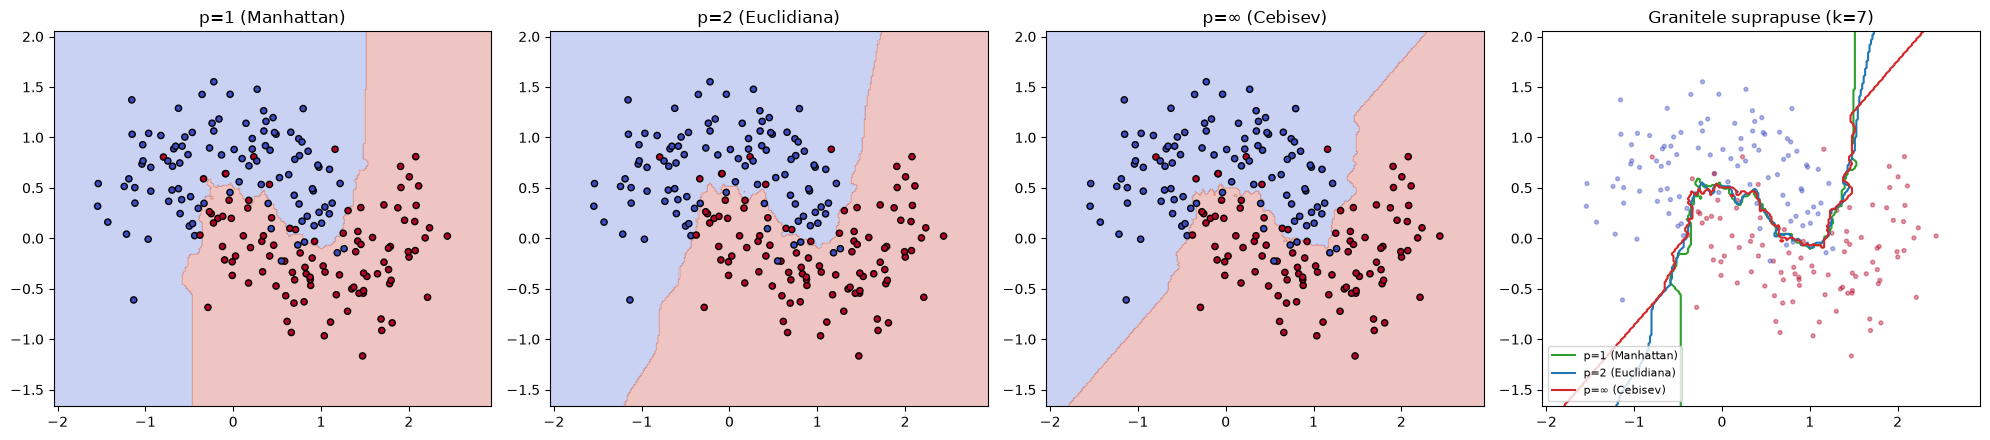

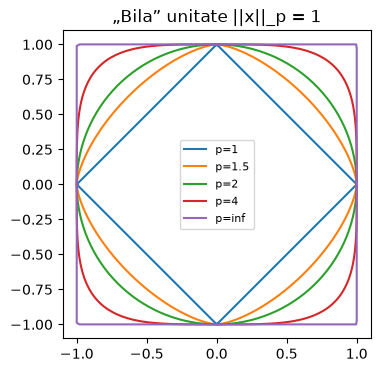

In [8]:
# Granitele de decizie pentru p = 1, 2, inf pe un set binar 2D
Xm, ym = make_moons(n_samples=200, noise=0.3, random_state=0)
xx, yy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 300),
                     np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
settings = [(1, 'p=1 (Manhattan)'), (2, 'p=2 (Euclidiana)'), (np.inf, 'p=∞ (Cebisev)')]
preds = {}
for ax, (p, title) in zip(axes, settings):
    knn = KNeighborsClassifier(n_neighbors=7, metric='chebyshev' if np.isinf(p) else 'minkowski',
                               **({} if np.isinf(p) else {'p': p})).fit(Xm, ym)
    Z = knn.predict(grid)
    # verificare: aceleasi predictii cu metrica proprie (functie Python) pe 300 de puncte din grila
    sample = grid[::300]
    custom = KNeighborsClassifier(n_neighbors=7, algorithm='brute',
                                  metric=lambda u, v, p=p: minkowski_distance(u, v, p)).fit(Xm, ym)
    print(f'{title}: metrica proprie = sklearn pe {np.mean(custom.predict(sample) == knn.predict(sample)):.0%} din puncte')
    preds[title] = Z
    ax.contourf(xx, yy, Z.reshape(xx.shape), alpha=0.3, cmap='coolwarm')
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap='coolwarm', edgecolor='k', s=20)
    ax.set_title(title)

# Suprapunerea granitelor + bila unitate pentru fiecare p
for (title, Z), col in zip(preds.items(), ['tab:green', 'tab:blue', 'tab:red']):
    axes[3].contour(xx, yy, Z.reshape(xx.shape), levels=[0.5], colors=col)
    axes[3].plot([], [], color=col, label=title)
axes[3].scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap='coolwarm', s=8, alpha=.4)
axes[3].legend(loc='lower left', fontsize=8); axes[3].set_title('Granitele suprapuse (k=7)')
plt.tight_layout()

t = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(4, 4))
for p in [1, 1.5, 2, 4, np.inf]:
    u = np.c_[np.cos(t), np.sin(t)]
    r = np.array([minkowski_distance(v, [0, 0], p) for v in u])
    ax.plot(u[:, 0] / r, u[:, 1] / r, label=f'p={p}')
ax.set_aspect('equal'); ax.legend(fontsize=8); ax.set_title('„Bila” unitate ||x||_p = 1')

print('Procent din grila unde predictia difera:')
names = list(preds)
for i in range(3):
    for j in range(i + 1, 3):
        print(f'  {names[i]} vs {names[j]}: {(preds[names[i]] != preds[names[j]]).mean():.2%}')

**Raspuns:**

- Pentru acelasi punct, $d_p$ scade cand $p$ creste: $d_1 = 7 \ge d_2 = 5 \ge d_3 = 4.50 \ge \dots \to d_\infty = \max_i |x_i - y_i| = 4$.
- "Bila" unitate $\{x: ||x||_p = 1\}$ este un romb pentru $p=1$, un cerc pentru $p=2$ si un patrat pentru $p=\infty$. Asta schimba cine sunt cei k vecini: $p=1$ favorizeaza vecinii aliniati pe o axa, $p=\infty$ ii favorizeaza pe cei de pe diagonala si ia in calcul doar diferenta cea mai mare.
- Granitele de decizie: pentru $p=1$ si $p=\infty$ granitele sunt formate din segmente orizontale/verticale si la 45°, iar pentru $p=2$ sunt mai netede. Diferentele apar mai ales langa zona de suprapunere a claselor (3.8% din grila difera intre p=1 si p=2, 7.3% intre p=1 si p=∞); in zonele clare predictia este aceeasi.

### Exercițiul 5: Paradoxul preciziei de 100% la K=3 pe eșantionul de antrenare
Așa cum s-a menționat în întrebarea 5 a notebook-ului, rularea KNN cu parametrul `weights='distance'` sau $K=1$ pe setul complet de date (fără împărțire train/test) oferă o precizie de 1.0 (100%). Explicați în detaliu fenomenul de memorare (supraantrenare extremă) în KNN. Ce se întâmplă cu cel mai apropiat vecin al punctului $x_i$ dacă eșantionul de antrenare include chiar punctul $x_i$?

In [9]:
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler

def load_churn():
    d = pd.read_csv('Orange_Telecom_Churn_Data - Orange_Telecom_Churn_Data.csv').drop(columns=['state', 'area_code', 'phone_number'])
    for col in ['intl_plan', 'voice_mail_plan', 'churned']:
        d[col] = LabelBinarizer().fit_transform(d[col]).ravel()
    return d.drop(columns='churned'), d['churned']

X_raw, y_all = load_churn()
X_all = pd.DataFrame(MinMaxScaler().fit_transform(X_raw), columns=X_raw.columns)
print(X_all.shape, '| churn rate = %.3f' % y_all.mean())

for k in [1, 3]:
    for w in ['uniform', 'distance']:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X_all, y_all)
        print(f'k={k}, weights={w:8s} -> acuratete pe datele de antrenare: {knn.score(X_all, y_all):.4f}')

# Cine este cel mai apropiat vecin al lui x_i?
knn1 = KNeighborsClassifier(n_neighbors=2).fit(X_all, y_all)
dist, idx = knn1.kneighbors(X_all)
print('\nPrimul vecin este chiar punctul insusi:', np.mean(idx[:, 0] == np.arange(len(X_all))) * 100, '% din cazuri')
print('Distanta la primul vecin: max =', dist[:, 0].max())
print('Distanta medie la al doilea vecin (adevaratul vecin): %.4f' % dist[:, 1].mean())

# Ponderea 1/d explodeaza cand d = 0
d_self = 1e-12
print('\nCu weights=distance, ponderea punctului insusi ≈ 1/%.0e = %.0e, fata de ~%.1f pentru ceilalti vecini'
      % (d_self, 1 / d_self, 1 / dist[:, 1].mean()))

(5000, 17) | churn rate = 0.141
k=1, weights=uniform  -> acuratete pe datele de antrenare: 1.0000
k=1, weights=distance -> acuratete pe datele de antrenare: 1.0000
k=3, weights=uniform  -> acuratete pe datele de antrenare: 0.9422
k=3, weights=distance -> acuratete pe datele de antrenare: 1.0000

Primul vecin este chiar punctul insusi: 100.0 % din cazuri
Distanta la primul vecin: max = 7.300048299977713e-08
Distanta medie la al doilea vecin (adevaratul vecin): 0.2670

Cu weights=distance, ponderea punctului insusi ≈ 1/1e-12 = 1e+12, fata de ~3.7 pentru ceilalti vecini


In [10]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.3, stratify=y_all, random_state=42)
rows = []
for k in [1, 3, 5, 10]:
    for w in ['uniform', 'distance']:
        m = KNeighborsClassifier(n_neighbors=k, weights=w).fit(Xtr, ytr)
        rows.append({'k': k, 'weights': w, 'acc_train': m.score(Xtr, ytr), 'acc_test': m.score(Xte, yte)})
pd.DataFrame(rows).round(3)

,k,weights,acc_train,acc_test
0,1,uniform,1.000,0.877
1,1,distance,1.000,0.877
2,3,uniform,0.941,0.904
3,3,distance,1.000,0.904
4,5,uniform,0.933,0.900
5,5,distance,1.000,0.899
6,10,uniform,0.906,0.898
7,10,distance,1.000,0.907


**Raspuns:**

Cand $x_i$ este in setul de antrenare si il evaluam tot pe el, cel mai apropiat vecin al sau este **chiar $x_i$**, la distanta $d = 0$ (confirmat mai sus: 100% din cazuri, distanta maxima ~$10^{-8}$, adica eroare de rotunjire). Deci:

- **K = 1:** predictia este eticheta lui $x_i$, iar acuratetea este 100%.
- **weights='distance':** ponderea este $1/d \to \infty$ pentru punctul insusi, deci votul lui domina oricati alti vecini ar fi (sklearn trateaza explicit cazul $d = 0$, dand pondere doar punctelor identice). Acuratete 100% pentru orice K.
- Cu `uniform` si K = 3, punctul insusi are doar 1 vot din 3, de aceea acuratetea scade la 0.942.

Acesta este overfitting extrem: KNN nu invata parametri, ci **memoreaza** setul de date. Pe datele de test, K = 1 are doar 0.877, iar `distance` cu K = 10 are 1.000 pe train, dar 0.907 pe test. Acuratetea pe train nu spune nimic despre generalizare; trebuie folosit train/test split sau cross-validation.

### Exercițiul 6: Implementarea propriului algoritm KNN de la zero
Fără a folosi clase din `sklearn`, scrieți propria clasă Python `CustomKNN` care implementează interfețele `fit(X, y)` și `predict(X_test, k)`. Clasa trebuie să utilizeze distanța euclidiană, să suporte votul majoritar simplu și să proceseze eficient matrici NumPy. Testați clasa pe o submulțime mică de date privind abandonul (churn).

In [ ]:
class CustomKNN:
    

    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        self.classes_, self._y_idx = np.unique(self.y_train, return_inverse=True)
        self._train_sq = np.sum(self.X_train ** 2, axis=1)
        return self

    def _distances(self, X_test):
        
        d2 = np.sum(X_test ** 2, axis=1)[:, None] + self._train_sq[None, :] - 2 * X_test @ self.X_train.T
        return np.sqrt(np.maximum(d2, 0))

    def predict(self, X_test, k=None, batch_size=1000):
        k = k or self.k
        X_test = np.asarray(X_test, dtype=float)
        preds = np.empty(len(X_test), dtype=int)
        for start in range(0, len(X_test), batch_size):   # procesare pe loturi -> memorie limitata
            D = self._distances(X_test[start:start + batch_size])
            nn = np.argpartition(D, kth=k - 1, axis=1)[:, :k]   # O(n) in loc de sortare completa
            votes = self._y_idx[nn]
            counts = np.apply_along_axis(np.bincount, 1, votes, minlength=len(self.classes_))
            preds[start:start + batch_size] = counts.argmax(axis=1)
        return self.classes_[preds]

    def score(self, X, y, k=None):
        return np.mean(self.predict(X, k) == np.asarray(y))


# Test pe o submultime mica a datelor de churn
from sklearn.model_selection import train_test_split
X_sub, y_sub = X_all.iloc[:1000].to_numpy(), y_all.iloc[:1000].to_numpy()
Xtr, Xte, ytr, yte = train_test_split(X_sub, y_sub, test_size=0.3, stratify=y_sub, random_state=0)

custom = CustomKNN().fit(Xtr, ytr)
for k in [1, 3, 5, 7]:
    y_c = custom.predict(Xte, k=k)
    y_s = KNeighborsClassifier(n_neighbors=k, algorithm='brute').fit(Xtr, ytr).predict(Xte)
    print(f'k={k}: CustomKNN acc = {np.mean(y_c == yte):.4f} | sklearn acc = {np.mean(y_s == yte):.4f} '
          f'| predictii identice: {np.mean(y_c == y_s):.1%}')

# Viteza pe tot setul de date
Xtr, Xte, ytr, yte = train_test_split(X_all.to_numpy(), y_all.to_numpy(), test_size=0.3, stratify=y_all, random_state=0)
t0 = time.perf_counter(); acc = CustomKNN(k=5).fit(Xtr, ytr).score(Xte, yte); t1 = time.perf_counter()
print(f'\nSet complet ({len(Xtr)} train / {len(Xte)} test), k=5: acc = {acc:.4f}, timp = {t1 - t0:.3f}s')

k=1: CustomKNN acc = 0.8867 | sklearn acc = 0.8867 | predictii identice: 100.0%
k=3: CustomKNN acc = 0.9167 | sklearn acc = 0.9167 | predictii identice: 100.0%
k=5: CustomKNN acc = 0.9133 | sklearn acc = 0.9133 | predictii identice: 100.0%
k=7: CustomKNN acc = 0.9000 | sklearn acc = 0.9000 | predictii identice: 100.0%

Set complet (3500 train / 1500 test), k=5: acc = 0.9013, timp = 0.061s


**Observatie:** `CustomKNN` produce exact aceleasi predictii ca `KNeighborsClassifier(algorithm='brute')`. Este eficienta datorita: (1) calculului tuturor distantelor ca inmultire de matrici $||a||^2 + ||b||^2 - 2ab^T$; (2) `argpartition` (O(n)) in loc de sortare completa; (3) procesarii pe loturi, ca matricea de distante sa nu ocupe prea multa memorie.

### Exercițiul 7: Validare încrucișată (Cross-Validation) pentru alegerea K-ului optim
Pentru a evita capcana evaluării pe eșantionul de antrenare, implementați procedura 5-Fold Cross-Validation utilizând `StratifiedKFold` din Scikit-learn. Scrieți un script care calculează precizia medie și deviația standard pentru valori K de la 1 la 30. Generați un grafic al erorilor de validare în funcție de K și determinați valoarea optimă.

K optim = 5: acuratete medie = 0.9034 ± 0.0043


k,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
acc_mean,0.8758,0.8904,0.8992,0.8912,0.9034,0.8914,0.8986,0.8928,0.9010,0.8946,...,0.8926,0.8874,0.8916,0.8878,0.8896,0.8868,0.8906,0.8870,0.8878,0.8854
acc_std,0.0099,0.0033,0.0048,0.0059,0.0043,0.0036,0.0036,0.0042,0.0046,0.0029,...,0.0047,0.0040,0.0045,0.0056,0.0050,0.0042,0.0040,0.0026,0.0032,0.0034
error,0.1242,0.1096,0.1008,0.1088,0.0966,0.1086,0.1014,0.1072,0.0990,0.1054,...,0.1074,0.1126,0.1084,0.1122,0.1104,0.1132,0.1094,0.1130,0.1122,0.1146


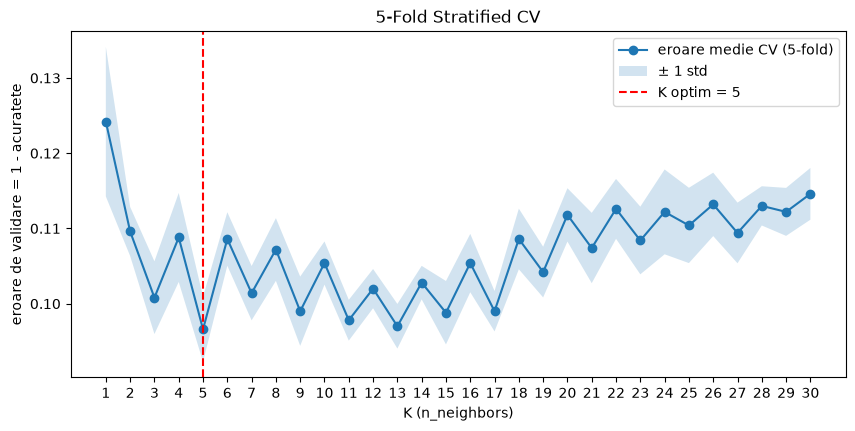

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for k in range(1, 31):
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_all, y_all, cv=skf, scoring='accuracy')
    cv_rows.append({'k': k, 'acc_mean': scores.mean(), 'acc_std': scores.std()})
cv_df = pd.DataFrame(cv_rows).set_index('k')
cv_df['error'] = 1 - cv_df['acc_mean']

best_k = cv_df['acc_mean'].idxmax()
print(f'K optim = {best_k}: acuratete medie = {cv_df.loc[best_k, "acc_mean"]:.4f} ± {cv_df.loc[best_k, "acc_std"]:.4f}')
display(cv_df.round(4).T)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cv_df.index, cv_df['error'], marker='o', label='eroare medie CV (5-fold)')
ax.fill_between(cv_df.index, cv_df['error'] - cv_df['acc_std'], cv_df['error'] + cv_df['acc_std'], alpha=.2, label='± 1 std')
ax.axvline(best_k, ls='--', c='red', label=f'K optim = {best_k}')
ax.set(xlabel='K (n_neighbors)', ylabel='eroare de validare = 1 - acuratete', title='5-Fold Stratified CV')
ax.set_xticks(range(1, 31)); ax.legend();

**Raspuns:** K optim = **5** (acuratete medie in CV 0.903 ± 0.004). Pentru K = 1 eroarea este cea mai mare (0.124), deoarece modelul este foarte sensibil la zgomot (varianta mare). Dupa K ≈ 9 eroarea creste lent, deoarece vecinii prea indepartati "netezesc" granita si clasa majoritara (86% "ramane") castiga mai des votul (bias mare). Se observa si un efect de paritate: valorile impare ale lui K sunt mai bune decat cele pare, deoarece la K par pot aparea egalitati de voturi, pe care sklearn le rezolva in favoarea clasei 0.

### Exercițiul 8: Lucrul cu clase dezechilibrate (Class Imbalance)
În setul de date Orange Telecom, clasa majoritară este reprezentată de clienții care nu au renunțat (`churned = False`), iar cei care au renunțat reprezintă minoritatea. Explicați de ce metrica `accuracy` (acuratețea) în acest context este înșelătoare. Modificați codul de evaluare pentru a calcula Matricea de Confuzie (Confusion Matrix), Precision, Recall și F1-score utilizând `sklearn.metrics`.

Distributia clasei: {0: 4293, 1: 707} -> 14.1% churn


,accuracy,precision,recall,f1
model,,,,
"Dummy (mereu ""nu pleaca"")",0.859,0.000,0.000,0.000
KNN k=5,0.900,0.782,0.406,0.534
"KNN k=5, distance",0.899,0.775,0.406,0.533


Raport detaliat pentru KNN k=5:
              precision    recall  f1-score   support

      ramane       0.91      0.98      0.94      1288
      pleaca       0.78      0.41      0.53       212

    accuracy                           0.90      1500
   macro avg       0.85      0.69      0.74      1500
weighted avg       0.89      0.90      0.89      1500



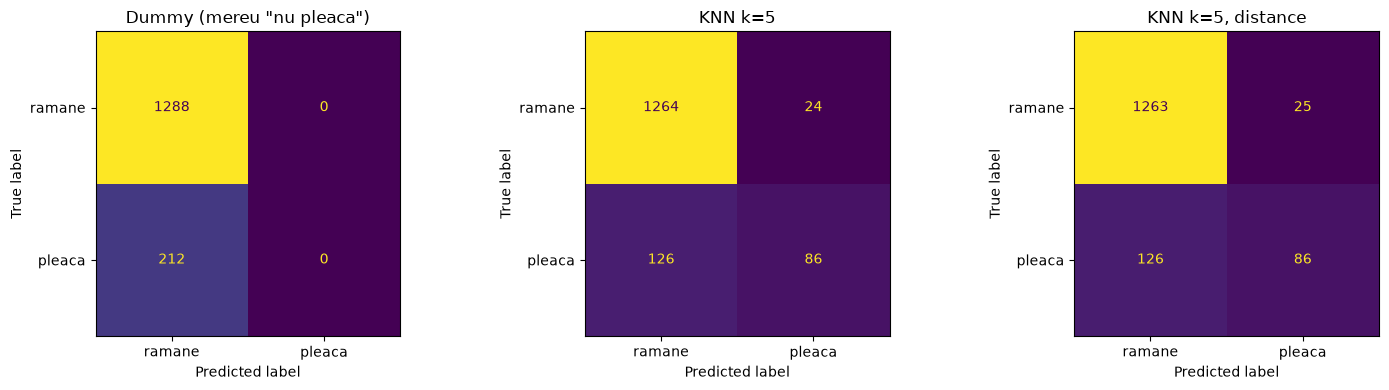

In [13]:
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.dummy import DummyClassifier

Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.3, stratify=y_all, random_state=42)
print('Distributia clasei:', y_all.value_counts().to_dict(), '-> %.1f%% churn' % (100 * y_all.mean()))

models = {
    'Dummy (mereu "nu pleaca")': DummyClassifier(strategy='most_frequent'),
    f'KNN k={best_k}': KNeighborsClassifier(n_neighbors=best_k),
    'KNN k=5, distance': KNeighborsClassifier(n_neighbors=5, weights='distance'),
}
rows = []
fig, axes = plt.subplots(1, len(models), figsize=(15, 4))
for ax, (name, m) in zip(axes, models.items()):
    y_hat = m.fit(Xtr, ytr).predict(Xte)
    rows.append({'model': name, 'accuracy': accuracy_score(yte, y_hat),
                 'precision': precision_score(yte, y_hat, zero_division=0),
                 'recall': recall_score(yte, y_hat), 'f1': f1_score(yte, y_hat)})
    ConfusionMatrixDisplay(confusion_matrix(yte, y_hat), display_labels=['ramane', 'pleaca']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
display(pd.DataFrame(rows).set_index('model').round(3))

print(f'Raport detaliat pentru KNN k={best_k}:')
print(classification_report(yte, models[f'KNN k={best_k}'].predict(Xte), target_names=['ramane', 'pleaca']))

**Raspuns:**

Doar 14.1% din clienti pleaca. Un model "prost" care prezice mereu "ramane" are deja **acuratete 0.859**, fara sa gaseasca niciun client care pleaca (recall = 0). KNN are acuratete 0.900, ceea ce pare mult, dar matricea de confuzie arata ca gaseste doar **41%** din clientii care pleaca (recall = 0.41), iar F1 pentru clasa "pleaca" este doar 0.53. Acuratetea este dominata de clasa majoritara si ascunde exact eroarea care ne intereseaza (clientii pierduti). Pentru churn sunt mai relevante **recall** (cati din cei care pleaca ii detectam), **precision** (cate alarme sunt corecte) si **F1** (media lor armonica), eventual si ajustarea pragului sau a ponderii claselor.

### Exercițiul 9: Impactul ponderilor distanței (`weights='distance'`) versus ponderi uniforme
Comparați comportamentul modelului KNN pentru `weights='uniform'` și `weights='distance'`. Scrieți un experiment în Python care evaluează sensibilitatea modelului la zgomot (valori anormale în spațiul caracteristicilor) pentru ambele tipuri de ponderi. Care variantă este mai vulnerabilă la zgomot și de ce?

accuracy               f1        
weights                          distance uniform distance uniform
zgomot                     nivel                                  
etichete inversate         0.00     0.900   0.900    0.505   0.508
                           0.05     0.898   0.898    0.509   0.511
                           0.10     0.890   0.891    0.493   0.495
                           0.20     0.856   0.857    0.423   0.424
                           0.30     0.777   0.777    0.355   0.356
outlieri in caracteristici 0.00     0.900   0.900    0.505   0.508
                           0.05     0.898   0.899    0.502   0.505
                           0.10     0.900   0.900    0.502   0.505
                           0.20     0.898   0.899    0.491   0.494
                           0.30     0.899   0.899    0.513   0.514

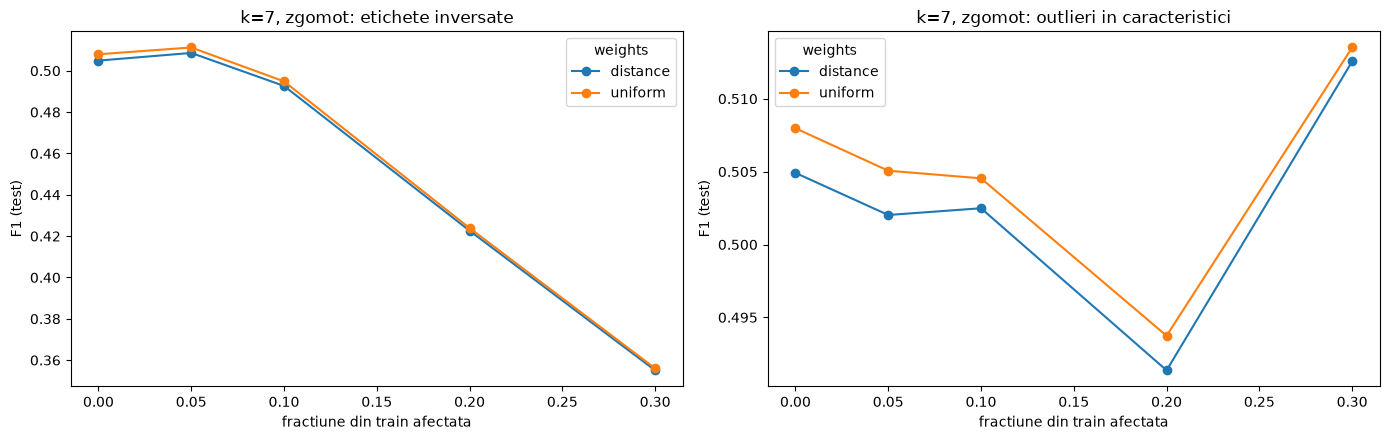

In [14]:
from sklearn.model_selection import train_test_split

def noise_experiment(kind, levels, k=7, seeds=range(5)):
    rows = []
    for level in levels:
        for seed in seeds:
            rng = np.random.default_rng(seed)
            Xtr, Xte, ytr, yte = train_test_split(X_all.to_numpy(), y_all.to_numpy(), test_size=0.3,
                                                  stratify=y_all, random_state=seed)
            Xtr, ytr = Xtr.copy(), ytr.copy()
            n_bad = int(level * len(Xtr))
            bad = rng.choice(len(Xtr), n_bad, replace=False)
            if kind == 'etichete inversate':
                ytr[bad] = 1 - ytr[bad]
            else:  # outlieri: puncte cu caracteristici perturbate puternic (zgomot gaussian, sigma=0.5)
                Xtr[bad] += rng.normal(0, 0.5, size=Xtr[bad].shape)
            for w in ['uniform', 'distance']:
                y_hat = KNeighborsClassifier(n_neighbors=k, weights=w).fit(Xtr, ytr).predict(Xte)
                rows.append({'zgomot': kind, 'nivel': level, 'weights': w,
                             'accuracy': accuracy_score(yte, y_hat), 'f1': f1_score(yte, y_hat)})
    return pd.DataFrame(rows)

levels = [0, 0.05, 0.10, 0.20, 0.30]
noise_df = pd.concat([noise_experiment('etichete inversate', levels),
                      noise_experiment('outlieri in caracteristici', levels)])
summary = noise_df.groupby(['zgomot', 'nivel', 'weights'])[['accuracy', 'f1']].mean().unstack('weights')
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, kind in zip(axes, noise_df['zgomot'].unique()):
    s = noise_df[noise_df['zgomot'] == kind].groupby(['nivel', 'weights'])['f1'].mean().unstack()
    s.plot(ax=ax, marker='o')
    ax.set(title=f'k=7, zgomot: {kind}', xlabel='fractiune din train afectata', ylabel='F1 (test)')
plt.tight_layout()

In [15]:
# Exemplu local: un singur outlier etichetat gresit langa un punct de test
Xp = np.array([[0.0, 0.0], [0.1, 0.0], [0.0, 0.1], [-0.1, 0.0], [0.0, -0.1], [0.32, 0.30]])
yp = np.array([0, 0, 0, 0, 0, 1])                     # ultimul punct = zgomot (eticheta gresita)
query = np.array([[0.30, 0.29]])                      # punct de test langa zgomot
for w in ['uniform', 'distance']:
    m = KNeighborsClassifier(n_neighbors=5, weights=w).fit(Xp, yp)
    print(f'{w:8s}: predictie = {m.predict(query)[0]}, P(clasa 1) = {m.predict_proba(query)[0, 1]:.2f}')

uniform : predictie = 0, P(clasa 1) = 0.20
distance: predictie = 1, P(clasa 1) = 0.82


**Raspuns:**

- In experimentul global (k = 7, media pe 5 impartiri) diferenta este mica: ambele variante pierd la fel de mult cand inversam etichete (F1 0.51 → 0.36 la 30% zgomot), iar `distance` este putin mai slaba la fiecare nivel. Outlierii mutati departe in spatiul caracteristicilor aproape nu conteaza: KNN este local, iar un punct indepartat nu ajunge printre vecinii punctelor de test.
- **`weights='distance'` este mai vulnerabila la zgomotul local.** Exemplul de mai sus arata cazul: un singur punct etichetat gresit, foarte aproape de punctul de test, primeste pondere $1/d$ foarte mare si schimba predictia (P = 0.82 pentru clasa gresita), desi 4 din 5 vecini spun clasa 0. Cu `uniform`, punctul are doar 1 vot din 5 (P = 0.20). Ponderarea dupa distanta face modelul sa se comporte ca un 1-NN in jurul fiecarui punct de antrenare (acuratete 100% pe train), deci are varianta mai mare. `uniform` mediaza mai bine zgomotul, dar poate fi influentata de vecini mai indepartati din alta clasa.

### Exercițiul 10: Blestemul dimensionalității (Curse of Dimensionality)
Algoritmul KNN se bazează pe măsurarea distanțelor în spații multidimensionale. Odată cu creșterea numărului de caracteristici, volumul spațiului crește exponențial, iar punctele devin echidistante. Scrieți un studiu de caz sau un experiment mic în Python care arată cum creșterea artificială a dimensionalității (adăugarea de coloane cu zgomot aleatoriu la datele de churn) înrăutățește performanța clasificatorului KNN.

,coloane_zgomot,dimensiune_totala,accuracy,f1
0,0,17,0.903,0.543
1,2,19,0.886,0.412
2,5,22,0.875,0.324
3,10,27,0.865,0.249
4,20,37,0.860,0.222
5,50,67,0.855,0.104
6,100,117,0.850,0.103
7,200,217,0.851,0.051
8,500,517,0.844,0.048


,d,contrast,std/mean
0,2,522.312,0.458
1,10,3.265,0.183
2,50,0.810,0.077
3,100,0.494,0.056
4,500,0.207,0.025
5,1000,0.147,0.017
6,5000,0.052,0.008


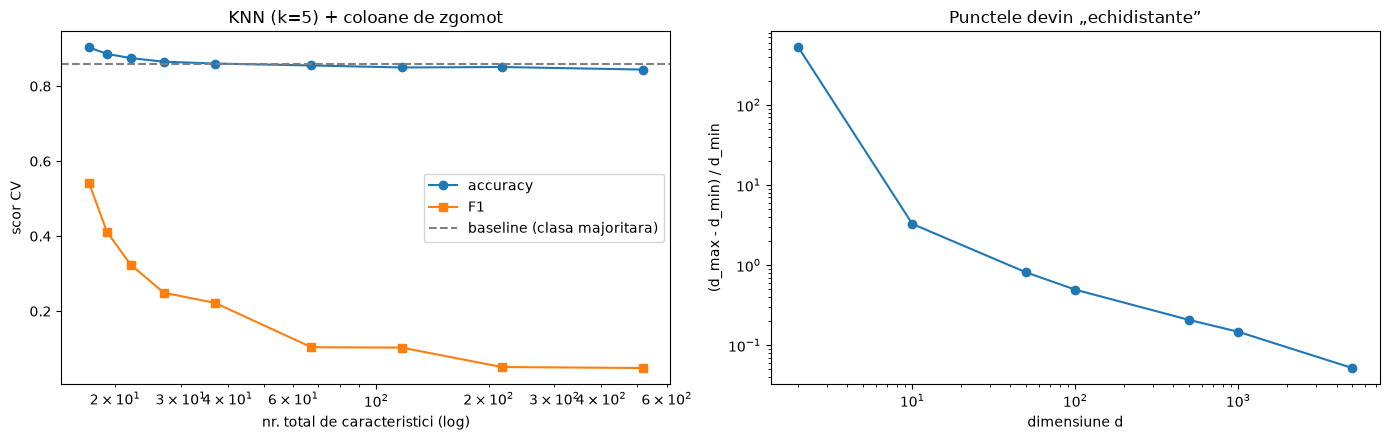

In [16]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rng = np.random.default_rng(0)
dims_rows = []
for n_noise in [0, 2, 5, 10, 20, 50, 100, 200, 500]:
    X_noisy = np.hstack([X_all.to_numpy(), rng.random((len(X_all), n_noise))])  # zgomot U[0,1], aceeasi scara
    knn = KNeighborsClassifier(n_neighbors=best_k)
    acc = cross_val_score(knn, X_noisy, y_all, cv=skf, scoring='accuracy').mean()
    f1 = cross_val_score(knn, X_noisy, y_all, cv=skf, scoring='f1').mean()
    dims_rows.append({'coloane_zgomot': n_noise, 'dimensiune_totala': X_noisy.shape[1], 'accuracy': acc, 'f1': f1})
dims_df = pd.DataFrame(dims_rows)
display(dims_df.round(3))

# Concentrarea distantelor: (d_max - d_min) / d_min pentru un punct de referinta
contrast = []
for d in [2, 10, 50, 100, 500, 1000, 5000]:
    P = rng.random((2000, d))
    dd = np.linalg.norm(P[1:] - P[0], axis=1)
    contrast.append({'d': d, 'contrast': (dd.max() - dd.min()) / dd.min(), 'std/mean': dd.std() / dd.mean()})
contrast_df = pd.DataFrame(contrast)
display(contrast_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(dims_df['dimensiune_totala'], dims_df['accuracy'], marker='o', label='accuracy')
axes[0].plot(dims_df['dimensiune_totala'], dims_df['f1'], marker='s', label='F1')
axes[0].axhline(1 - y_all.mean(), ls='--', c='gray', label='baseline (clasa majoritara)')
axes[0].set(xscale='log', xlabel='nr. total de caracteristici (log)', ylabel='scor CV', title=f'KNN (k={best_k}) + coloane de zgomot')
axes[0].legend()
axes[1].plot(contrast_df['d'], contrast_df['contrast'], marker='o')
axes[1].set(xscale='log', yscale='log', xlabel='dimensiune d', ylabel='(d_max - d_min) / d_min',
            title='Punctele devin „echidistante”');
plt.tight_layout()

**Raspuns:**

- Adaugarea de coloane aleatoare in [0, 1] (aceeasi scara ca datele reale) scade rapid performanta: F1 0.543 → 0.249 la 10 coloane de zgomot → 0.048 la 500. Acuratetea scade spre baseline-ul de 0.859, adica modelul ajunge sa prezica aproape mereu "ramane".
- Cauza: distanta euclidiana aduna contributia tuturor dimensiunilor. Cele 17 caracteristici utile sunt "inecate" de suma diferentelor aleatoare, deci vecinii gasiti nu mai sunt clienti cu adevarat asemanatori.
- **Concentrarea distantelor:** raportul $(d_{max} - d_{min}) / d_{min}$ scade de la 522 (d = 2) la 0.05 (d = 5000): toate punctele ajung aproape la aceeasi distanta, deci notiunea de "cel mai apropiat vecin" isi pierde sensul. De aceea KNN are nevoie de selectie de caracteristici sau reducerea dimensionalitatii (vezi `SelectKBest` in Ex. 12).

### Exercițiul 11: KNN pentru regresie versus clasificare
Deși în notebook am folosit `KNeighborsClassifier` pentru o sarcină de clasificare binară, KNN este aplicabil și pentru regresie (`KNeighborsRegressor`). Scrieți un script care aplică `KNeighborsRegressor` pentru a prezice o variabilă continuă (de exemplu, `total_day_charges` pe baza minutelor și a apelurilor). Comparați funcția de pierdere (MSE — Mean Squared Error) pentru diferite valori ale lui K.

Varianta tintei (MSE al unui model care prezice media): 83.944


MSE_train                      \
caracteristici doar apeluri (zi, seara, noapte) minute + apeluri zi   
k                                                                     
1                                         1.175               0.000   
2                                        41.686               0.039   
3                                        55.615               0.058   
5                                        64.970               0.078   
10                                       73.605               0.131   
20                                       78.530               0.257   
50                                       81.729               0.691   
100                                      82.234               1.390   
200                                      82.548               2.848   

                                       MSE_test                      \
caracteristici doar apeluri (zi, seara, noapte) minute + apeluri zi   
k                                                                     
1                                       160.181               0.846   
2                                       120.596               0.672   
3                                       108.794               0.697   
5                                       101.223               0.469   
10                                       92.902               0.558   
20                                       87.687               0.712   
50                                       86.201               1.280   
100                                      86.024               2.071   
200                                      85.613               3.684   

                                        R2_test                      
caracteristici doar apeluri (zi, seara, noapte) minute + apeluri zi  
k                                                                    
1                                        -0.864               0.990  
2                                        -0.403               0.992  
3                                        -0.266               0.992  
5                                        -0.178               0.995  
10                                       -0.081               0.994  
20                                       -0.020               0.992  
50                                       -0.003               0.985  
100                                      -0.001               0.976  
200                                       0.004               0.957

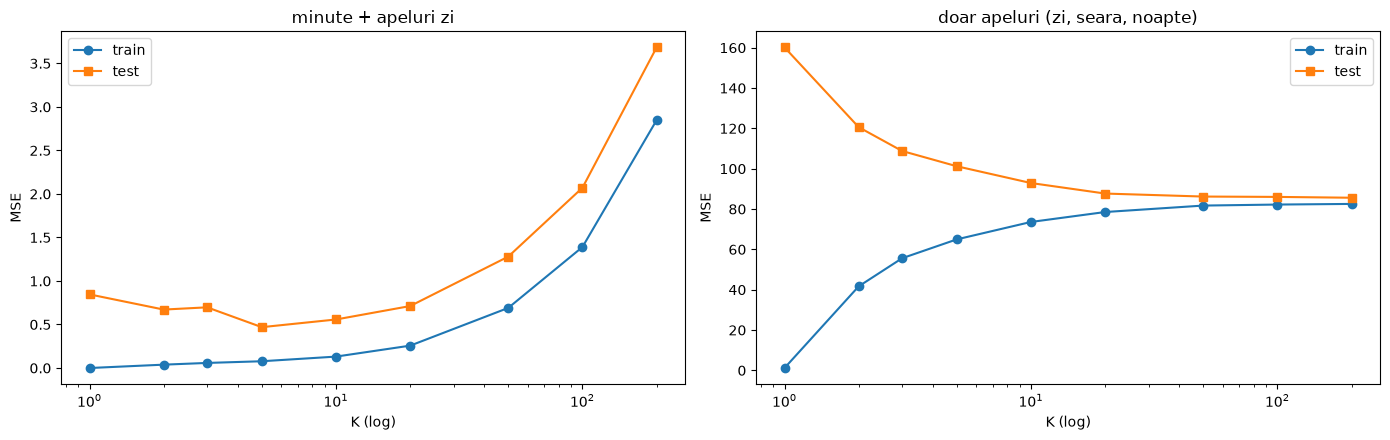

In [17]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline

df = pd.read_csv('Orange_Telecom_Churn_Data - Orange_Telecom_Churn_Data.csv')
feature_sets = {
    'minute + apeluri zi': ['total_day_minutes', 'total_day_calls'],
    'doar apeluri (zi, seara, noapte)': ['total_day_calls', 'total_eve_calls', 'total_night_calls'],
}
y_reg = df['total_day_charge']
print('Varianta tintei (MSE al unui model care prezice media): %.3f' % y_reg.var())

reg_rows = []
for fs_name, cols in feature_sets.items():
    Xtr, Xte, ytr, yte = train_test_split(df[cols], y_reg, test_size=0.3, random_state=42)
    for k in [1, 2, 3, 5, 10, 20, 50, 100, 200]:
        model = make_pipeline(MinMaxScaler(), KNeighborsRegressor(n_neighbors=k)).fit(Xtr, ytr)
        reg_rows.append({'caracteristici': fs_name, 'k': k,
                         'MSE_train': mean_squared_error(ytr, model.predict(Xtr)),
                         'MSE_test': mean_squared_error(yte, model.predict(Xte)),
                         'R2_test': r2_score(yte, model.predict(Xte))})
reg_df = pd.DataFrame(reg_rows)
display(reg_df.pivot(index='k', columns='caracteristici', values=['MSE_train', 'MSE_test', 'R2_test']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, fs_name in zip(axes, feature_sets):
    s = reg_df[reg_df['caracteristici'] == fs_name].set_index('k')
    ax.plot(s.index, s['MSE_train'], marker='o', label='train')
    ax.plot(s.index, s['MSE_test'], marker='s', label='test')
    ax.set(xscale='log', xlabel='K (log)', ylabel='MSE', title=fs_name); ax.legend()
plt.tight_layout()

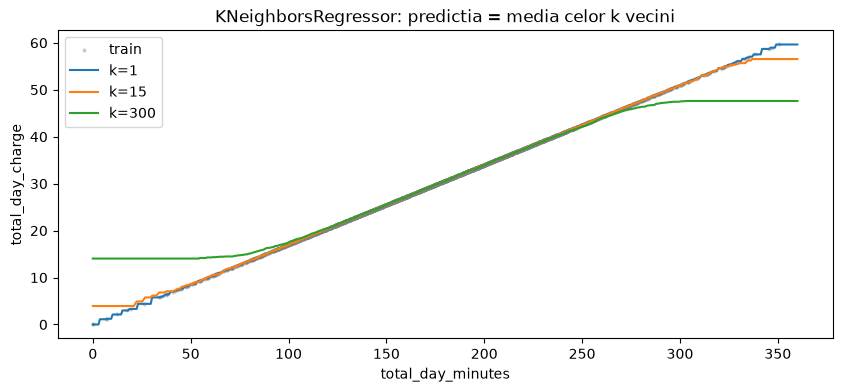

In [18]:
# Clasificare vs regresie pe acelasi K: vot majoritar vs medie a vecinilor
Xtr, Xte, ytr, yte = train_test_split(df[['total_day_minutes']], y_reg, test_size=0.3, random_state=0)
grid_x = pd.DataFrame({'total_day_minutes': np.linspace(0, 360, 500)})
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(Xtr, ytr, s=4, alpha=.3, c='gray', label='train')
for k in [1, 15, 300]:
    ax.plot(grid_x, KNeighborsRegressor(n_neighbors=k).fit(Xtr, ytr).predict(grid_x), label=f'k={k}')
ax.set(xlabel='total_day_minutes', ylabel='total_day_charge', title='KNeighborsRegressor: predictia = media celor k vecini')
ax.legend();

**Raspuns:**

- `KNeighborsRegressor` prezice **media** valorilor tinta ale celor k vecini, in loc de vot majoritar, si se evalueaza cu MSE in loc de acuratete.
- **Minute + apeluri zi:** `total_day_charge` este practic proportional cu `total_day_minutes`, deci predictia este foarte buna (R² ≈ 0.99). K = 1 are MSE_train = 0 (memorare), dar MSE_test = 0.85; minimul pe test este la **K = 5 (MSE = 0.47)**; pentru K mare (200) eroarea creste la 3.68, deoarece media pe vecini prea indepartati netezeste prea mult (bias).
- **Doar apeluri:** numarul de apeluri nu explica factura, deci MSE_test (85-160) nu coboara sub varianta tintei (83.9) - modelul nu e mai bun decat media. La K = 1 MSE_test este de 2 ori mai mare decat varianta (overfitting pe zgomot). Acelasi compromis bias-varianta ca la clasificare: K mic → varianta mare, K mare → bias mare.

### Exercițiul 12: Conducte de învățare automată cu `Pipeline` și `GridSearchCV`
Construiți o conductă (pipeline) completă în Scikit-learn care include: (1) `MinMaxScaler`, (2) opțional un selector de caracteristici (`SelectKBest`) și (3) `KNeighborsClassifier`. Utilizați `GridSearchCV` pentru căutarea simultană a hiperparametrilor optimi: numărul de vecini K din {3, 5, 7, 9, 11}, tipul de ponderi (`uniform`, `distance`) și metrica distanței (p=1 sau p=2). Afișați cel mai bun set de hiperparametri și scorul pe eșantionul de test.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

X_raw, y_all = load_churn()      # date NEscalate: scalarea se face in interiorul pipeline-ului
Xtr, Xte, ytr, yte = train_test_split(X_raw, y_all, test_size=0.25, stratify=y_all, random_state=42)

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier()),
])
param_grid = {
    'select__k': [5, 8, 12, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}
gs = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                  scoring={'f1': 'f1', 'accuracy': 'accuracy'}, refit='f1', n_jobs=-1)
gs.fit(Xtr, ytr)

print('Cel mai bun set de hiperparametri:', gs.best_params_)
print('F1 mediu in CV: %.4f' % gs.best_score_)
best = gs.best_estimator_
y_hat = best.predict(Xte)
print('\nPe esantionul de TEST:  accuracy = %.4f | F1 = %.4f | precision = %.4f | recall = %.4f'
      % (accuracy_score(yte, y_hat), f1_score(yte, y_hat), precision_score(yte, y_hat), recall_score(yte, y_hat)))
print('Caracteristici selectate:', list(Xtr.columns[best.named_steps['select'].get_support()]))

res = pd.DataFrame(gs.cv_results_)
cols = ['param_select__k', 'param_knn__n_neighbors', 'param_knn__weights', 'param_knn__p',
        'mean_test_f1', 'mean_test_accuracy', 'rank_test_f1']
display(res[cols].sort_values('rank_test_f1').head(10).round(4))
print(classification_report(yte, y_hat, target_names=['ramane', 'pleaca']))

Cel mai bun set de hiperparametri: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'distance', 'select__k': 8}
F1 mediu in CV: 0.6340

Pe esantionul de TEST:  accuracy = 0.9000 | F1 = 0.5955 | precision = 0.6970 | recall = 0.5198
Caracteristici selectate: ['intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_charge', 'total_eve_minutes', 'total_eve_charge', 'number_customer_service_calls']


,param_select__k,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_f1,mean_test_accuracy,rank_test_f1
37,8,7,distance,1,0.6340,0.9104,1
2,12,3,uniform,1,0.6317,0.9128,2
6,12,3,distance,1,0.6310,0.9123,3
10,12,3,uniform,2,0.6304,0.9128,4
14,12,3,distance,2,0.6269,0.9117,5
22,12,5,distance,1,0.6253,0.9160,6
45,8,7,distance,2,0.6244,0.9080,7
18,12,5,uniform,1,0.6237,0.9157,8
53,8,9,distance,1,0.6236,0.9091,9
33,8,7,uniform,1,0.6195,0.9096,10


              precision    recall  f1-score   support

      ramane       0.92      0.96      0.94      1073
      pleaca       0.70      0.52      0.60       177

    accuracy                           0.90      1250
   macro avg       0.81      0.74      0.77      1250
weighted avg       0.89      0.90      0.89      1250



**Raspuns:**

- Cel mai bun set (dupa F1 in CV, ales din cauza dezechilibrului de clase din Ex. 8): **SelectKBest k = 8, n_neighbors = 7, weights = 'distance', p = 1 (Manhattan)**. F1 in CV = 0.634.
- Pe **testul** separat: accuracy = 0.900, F1 = 0.596, recall = 0.52 - fata de F1 ≈ 0.53 si recall 0.41 pentru KNN cu toate caracteristicile (Ex. 8).
- Imbunatatirea vine din **selectia caracteristicilor**: pastram doar cele 8 relevante (planuri, minute/costuri de zi si seara, apeluri la serviciul clienti) si eliminam cele care adauga doar zgomot la distanta (efectul din Ex. 10).
- `Pipeline` asigura ca `MinMaxScaler` si `SelectKBest` sunt antrenate doar pe fold-urile de antrenare din fiecare split al CV, deci nu exista scurgere de informatie (data leakage) din datele de validare sau test.